In [140]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from fdm_solver import State

plt.rcParams.update({
    # "text.usetex": True,
    # "font.family": "serif",
    "text.usetex": False,
    "mathtext.fontset": "stix",
    "font.family": "STIXGeneral",
    "axes.linewidth": 2,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.minor.width": 2,
    "ytick.minor.width": 2,
})

In [ ]:
""" Plotting function """
def plot_initial(state):
    fig = plt.figure(2)
    ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
    ax.plot(state.x / L, state.u_initial, linewidth=2, color="black",
            linestyle="solid", label=r"t = 0", zorder=1)
    ax.set_xlabel(r"$x / L$", fontsize=18)
    ax.set_ylabel(r"$u / u_0$", fontsize=18)
    ax.set_xlim(-0.5, 0.5)
    ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
    ax.set_xticklabels([-0.5, -0.25, 0, 0.25, 0.5])
    ax.tick_params(axis="both", labelsize=18)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.legend(loc="best", frameon=False, fontsize=18)
    plt.show()


def plot_solution(state, t, analytical_func, analytical_params):
    u_an = analytical_func(state.x, t, *analytical_params)
    fig = plt.figure(2)
    ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
    ax.plot(state.x / state.L, u_an, linewidth=2, color="black",
            linestyle="solid", label=r"Analytical")
    ax.scatter(
        state.x / state.L, state.u[t], s=50, linewidth=2,
        edgecolor="red", facecolor="none", linestyle="solid",
        label=r"t = " + str(t)
    )
    ax.set_xlabel(r"$x / L$", fontsize=18)
    ax.set_ylabel(r"$u / u_0$", fontsize=18)
    ax.set_xlim(-0.5, 0.5)
    ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
    ax.set_xticklabels([-0.5, -0.25, 0, 0.25, 0.5])
    ax.tick_params(axis="both", labelsize=18)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.legend(loc="best", frameon=False, fontsize=18)
    plt.savefig("figures/fdm_comparison_analytical.pdf")
    plt.show()

# Initial condition: $C = \delta(x)$

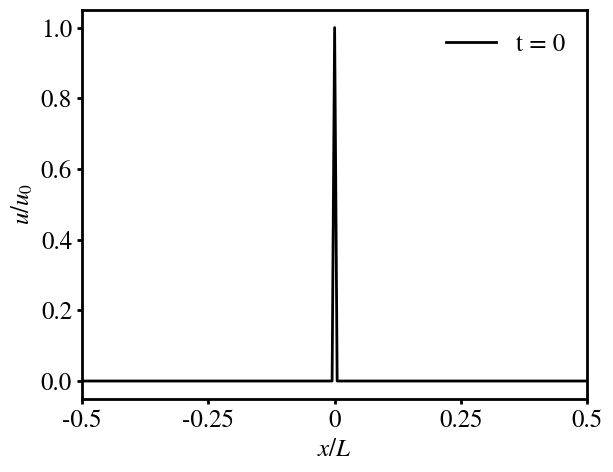

In [142]:
L = 200
state = State(L)
state.initialize(lambda x: np.where(x == 0, 1, 0), ())
plot_initial(state)

# Solve and compare with analytical solution

In [143]:
iterations = 100
D = 0.4
state.evolve(iterations, D)

Solving system in time
Chosen Fourier number: 0.4 <= 0.5
Stable discretization!
Solution complete!


### Analytical solution:
Analytical solution for the scalar quantity $u$ is a Gaussian centered at $x = x_0$ with standard deviation $\sqrt{2 D t}$, and is written as
\begin{align}
    u(x, t) = \dfrac{u_0}{\sqrt{4 \pi D t}} \exp{\left [- \dfrac{(x - x_0)^2}{4 D t} \right ]}
\end{align}
where $D = 0.4$ is diffusivity, $x_0 = 0$ is the spatial point at which the Gaussuian distribution is centered, and $t$ is time.

In [144]:
def analytical(x, t, x_0, u_0, D):
    return (
        (u_0 / np.sqrt(4 * np.pi * D * t)) * 
        np.exp(-(x - x_0)**2 / (4 * D * t))
    )

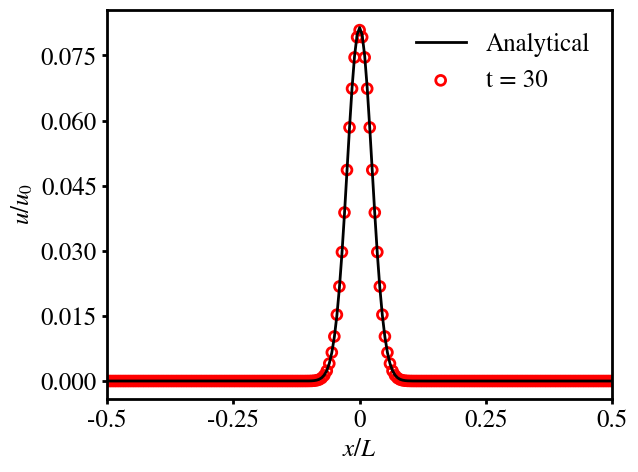

In [145]:
plot_solution(state, 30, analytical, (0, 1, D))